In [3]:
import numpy 
import matplotlib.pyplot as plt  
import os 
import pandas as pd 
import numpy as np  


from sklearn.model_selection import train_test_split

np.random.seed(123)  # For reproducibility

### Data preparation 

In [5]:
# Load the insurance data , should be in the same directory as this script
insurance_data = pd.read_csv('data/insurance_data_raw.csv')

insurance_data = insurance_data.sample(frac=1).reset_index(drop=True)
# Separate features and target variable
target = insurance_data["claim"].values


insurance_data.head(n=9)


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
0,56.0,male,56,33.7,NoDisease,4,0,Charleston,74,1,0,HouseKeeper,12949.2
1,56.0,female,66,37.5,NoDisease,2,0,WashingtonDC,82,1,0,CEO,12265.5
2,48.0,male,51,NaN,NoDisease,3,0,Memphis,74,1,0,Farmer,10141.1
3,59.0,female,75,27.8,NoDisease,3,0,Charleston,80,1,1,Dancer,14001.3
4,38.0,female,88,40.6,NoDisease,1,0,Oceanside,72,1,0,Politician,6373.6
5,47.0,male,89,29.8,NoDisease,3,0,Chicago,0,1,1,Technician,9620.3
6,53.0,male,71,29.2,NoDisease,0,0,Boston,78,1,0,Student,10072.1
7,53.0,male,60,36.1,NoDisease,1,0,Cambridge,64,1,1,Lawyer,10085.9
8,41.0,male,95,29.6,NoDisease,5,0,Louisville,62,1,0,ITProfessional,9222.4


In [7]:
from sklearn.preprocessing import LabelEncoder

# Remove 'claim' column
insurance_data_no_claim = insurance_data.drop(columns=['claim'])
# Encode string columns to integer
string_columns = insurance_data_no_claim.select_dtypes(include='object').columns
label_encoders = {}

for col in string_columns:
    le = LabelEncoder()
    insurance_data_no_claim[col] = le.fit_transform(insurance_data_no_claim[col])
    label_encoders[col] = le

insurance_data_no_claim.head()

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
0,56.0,1,56,33.7,8,4,0,12,74,1,0,23
1,56.0,0,66,37.5,8,2,0,86,82,1,0,9
2,48.0,1,51,NaN,8,3,0,47,74,1,0,17
3,59.0,0,75,27.8,8,3,0,12,80,1,1,12
4,38.0,0,88,40.6,8,1,0,57,72,1,0,31


In [8]:
# How to handle missing values ####
insurance_data_no_claim.isna().sum() 
#get the number of missing values in each column
#insurance_data_no_claim = insurance_data_no_claim.dropna()  # Drop rows with missing values
insurance_data_no_claim = insurance_data_no_claim.fillna(insurance_data_no_claim.mean())  # Fill missing values with column mean


# Receive a summary of the dataframe ####
# insurance_data_no_claim.info() get a summary of the dataframe
# insurance_data_no_claim.describe() get a statistical summary of the dataframe

print(insurance_data_no_claim.isna().sum())


age                    0
sex                    0
weight                 0
bmi                    0
hereditary_diseases    0
no_of_dependents       0
smoker                 0
city                   0
bloodpressure          0
diabetes               0
regular_ex             0
job_title              0
dtype: int64


In [9]:
insurance_data_no_claim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  15000 non-null  float64
 1   sex                  15000 non-null  int32  
 2   weight               15000 non-null  int64  
 3   bmi                  15000 non-null  float64
 4   hereditary_diseases  15000 non-null  int32  
 5   no_of_dependents     15000 non-null  int64  
 6   smoker               15000 non-null  int64  
 7   city                 15000 non-null  int32  
 8   bloodpressure        15000 non-null  int64  
 9   diabetes             15000 non-null  int64  
 10  regular_ex           15000 non-null  int64  
 11  job_title            15000 non-null  int32  
dtypes: float64(2), int32(4), int64(6)
memory usage: 1.1 MB


### Feature engineering  

In [10]:
# Discard not significant features

#if "index" in insurance_data_no_claim.columns or "PatientID" in insurance_data_no_claim.columns:
features = insurance_data_no_claim  #.drop(columns=['index', 'PatientID'])


# Standardize numerical features
features["age"] = (features["age"] - features["age"].mean()) / features["age"].std()
features["bloodpressure"] = (features["bloodpressure"] - features["bloodpressure"].mean()) / features["bloodpressure"].std()
features["bmi"] = (features["bmi"] - features["bmi"].mean()) / features["bmi"].std()


features = features[["age", "smoker", "bmi", "hereditary_diseases"]]

# Normalize to [0,1]
max_target = target.max()

target = target / max_target    
target_ind = target.copy()


# Split the dataset into training, validation, and test sets ####
from sklearn.model_selection import train_test_split

# Split the data into train, validation, and test sets (e.g., 60% train, 20% val, 20% test)

# First split into train and temp (train: 60%, temp: 40%)
X_temp, X_test, y_temp, y_test = train_test_split(features, target, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)  # 0.25 x 0.8 = 0.2

print("Train set size:", X_train.shape)
print("Validation set size:", X_val.shape)
print("Test set size:", X_test.shape)

Train set size: (9000, 4)
Validation set size: (3000, 4)
Test set size: (3000, 4)


In [11]:
xgb.XGBClassifier(data= features, label=target)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None,
              data=            age  smoker       bmi  hereditary_diseases
0      1.189648       0  0.579547                    8
1      1.189648       0  1.220940                    8
2      0.611183       0  0.000000                    8
3      1.406572       0 -0.416300                    8
4     -0.111898       0  1.744181                    8
...         ...     ...       ...                  ...
14995 -1.558061       1 -0.652602                    1
14996  1.623497       0  1.322212                    8
14997 -0.328823       0 -0.450057                    8
1499...
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None,
              label=array([0.20305973, 0.19233845, 0.15902519, ..., 0.07444049, 0.22572228,
       0.19804172]),
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None, ...)

In [ ]:
#features.to_csv("data/insurance_data_mod.csv")

In [12]:
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

# Features (insurance_data_no_claim) und Zielvariable (target) verwenden
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Vorhersage für die Trainingsdaten
predictions = lin_reg.predict(X_test)

# Beispiel: Ausgabe der ersten 5 Vorhersagen
print(predictions[:5])
print(y_test[:5] )

from sklearn.metrics import mean_squared_error


# Train Linear Regression on training set
lin_reg_val = LinearRegression()
lin_reg_val.fit(X_train, y_train)

# Predict on validation set
val_predictions = lin_reg_val.predict(X_val)
lin_pred = lin_reg_val.predict(X_test)

# Output first 5 predictions and ground truth
print("Validation predictions:", np.round(val_predictions[:5], 3) )
print("Validation ground truth:",np.round(y_val[:5], 3))

# Calculate MSE for validation set
mse_val = mean_squared_error(y_val, val_predictions)
print("Validation Mean Squared Error 10^3:", mse_val * 10**3)


# Calculate MSE for test set
mse_test = mean_squared_error(y_test, lin_pred)
print("Test Mean Squared Error 10^3:", mse_test * 10**3)

[0.19431086 0.05088068 0.17339629 0.18294927 0.48754205]
[0.18709464 0.02571099 0.16344417 0.18551867 0.36696179]
Validation predictions: [0.149 0.441 0.104 0.195 0.143]
Validation ground truth: [0.135 0.582 0.085 0.166 0.075]
Validation Mean Squared Error 10^3: 9.157470804672135
Test Mean Squared Error 10^3: 9.68494229522167


Explained variance ratio per component: [0.3516 0.2945 0.2041 0.1499]
Cumulative explained variance: [0.3516 0.646  0.8501 1.    ]


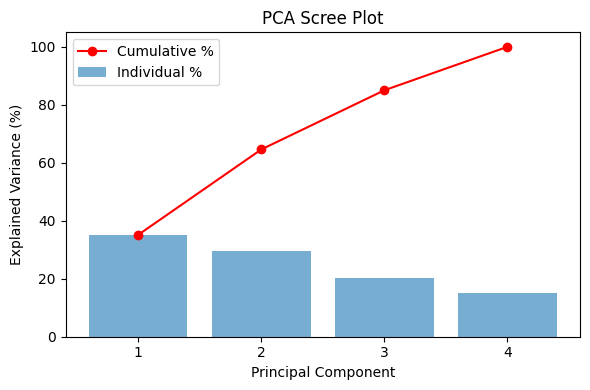

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Prepare data
insurance_data_no_claim = features.copy()  # use existing processed DataFrame
scaler = StandardScaler()
X_scaled = scaler.fit_transform(insurance_data_no_claim)

# Full PCA to inspect explained variance
pca_full = PCA()
pca_full.fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = explained.cumsum()

print("Explained variance ratio per component:", np.round(explained, 4))
print("Cumulative explained variance:", np.round(cumulative, 4))

# Scree plot
plt.figure(figsize=(6,4))
plt.bar(range(1, len(explained)+1), explained * 100, alpha=0.6, label='Individual %')
plt.plot(range(1, len(cumulative)+1), cumulative * 100, marker='o', color='red', label='Cumulative %')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA Scree Plot')
plt.xticks(range(1, len(explained)+1))
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
def removeElement(nums , val):
    val_list = []
    final_list = []
    for i, value in enumerate(nums):
        if value == val: 
            val_list.append("_")
        else:
            final_list.append(value)
    final_list = final_list  + val_list 
    return final_list 


nums = [0,1,2,2,3,0,4,2]
val = 2

result = removeElement(nums, val)
print("Result after removing value {}: {}".format(val, result))


Result after removing value 2: [0, 1, 3, 0, 4, '_', '_', '_']


In [16]:
#python train_model.py# PCA to 2 components for visualization
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

# Scatter plot of first 2 principal components, colored by the selected column (e.g. region)
col_values = insurance_data_no_claim[col].values  # 'col' variable exists in the notebook and equals 'region'
unique_vals = np.unique(col_values)


# Optionally display loadings for first two components
loadings = pd.DataFrame(pca2.components_.T, index=X_train.columns, columns=['PC1', 'PC2'])
print("Top loadings (absolute) for PC1 and PC2:")
print(loadings.abs().sort_values('PC1', ascending=False).head(8))
print(loadings.abs().sort_values('PC2', ascending=False).head(8))

KeyError: 'job_title'